# Blok 2 · Część 1 — Rzetelna ocena modelu

**Uczenie maszynowe w Pythonie** — Politechnika Gdańska, 2026

Na Zajęciach 1 zbudowaliśmy model i ocenialiśmy go **jedną liczbą na jednym podziale**. Dziś uczymy się, jak zrobić to jeszcze bardziej wiarygodnie.

**Plan:**
1. Walidacja krzyżowa — jak odróżnić poprawę od szczęścia w losowaniu
2. Metryki klasyfikacji — co mierzyć, gdy accuracy kłamie
3. Metryki regresji — więcej niż RMSE i MAE
4. Kalibracja — czy `predict_proba` to naprawdę prawdopodobieństwo?

**Dane:** znane z Zajęć 1 — rezerwacje hoteli (klasyfikacja) i California Housing (regresja). Modele: tylko liniowe, żeby skupić się na **ocenie**, a nie na algorytmie.

## 0. Przygotowanie

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


import warnings
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings("ignore", category=UndefinedMetricWarning) 

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")

print("scikit-learn", sklearn.__version__)   # potrzebujemy >= 1.4

scikit-learn 1.9.1


In [37]:
# dane z Zajęć 1: lokalnie z repo, w Colabie z GitHuba
URL = "https://raw.githubusercontent.com/ml-course-pg/ml-course-pg-2026/main/01-wprowadzenie/data/"

def wczytaj(nazwa):
    try:
        return pd.read_csv(f"../01-wprowadzenie/data/{nazwa}")
    except FileNotFoundError:
        return pd.read_csv(URL + nazwa)

hotele = wczytaj("hotels.csv")
kalifornia = wczytaj("california_housing.csv")
print("hotele:    ", hotele.shape, f"  anulowanych: {hotele['is_canceled'].mean():.1%}")
print("kalifornia:", kalifornia.shape)

hotele:     (10000, 28)   anulowanych: 37.0%
kalifornia: (20433, 9)


Pipeline dla hoteli bierzemy **dokładnie z rozwiązania zadania z Zajęć 1**. Zamykamy go w funkcji, żeby łatwo budować warianty.

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression

CECHY_NUM = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
             "adults", "children", "babies", "is_repeated_guest",
             "previous_cancellations", "previous_bookings_not_canceled",
             "days_in_waiting_list", "adr",
             "required_car_parking_spaces", "total_of_special_requests"]
CECHY_KAT = ["hotel", "meal", "market_segment", "distribution_channel",
             "reserved_room_type", "deposit_type", "customer_type"]

def zbuduj_model(cechy_kat=CECHY_KAT, C=1.0, class_weight=None):
    pipe_num = Pipeline([
        ("imputacja", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("skalowanie", StandardScaler()),
    ])
    pipe_kat = Pipeline([
        ("imputacja", SimpleImputer(strategy="most_frequent")),
        ("kodowanie", OneHotEncoder(handle_unknown="ignore")),
    ])
    pipe_rzadkie = Pipeline([
        ("imputacja", SimpleImputer(strategy="most_frequent")),
        ("kodowanie", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)),
    ])
    pipe_id = Pipeline([
        ("imputacja", SimpleImputer(strategy="constant", fill_value=-1)),
        ("kodowanie", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)),
    ])
    preprocessing = ColumnTransformer([
        ("numeryczne", pipe_num, CECHY_NUM),
        ("kategoryczne", pipe_kat, list(cechy_kat)),
        ("country", pipe_rzadkie, ["country"]),
        ("agent", pipe_id, ["agent"]),
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("klasyfikator", LogisticRegression(C=C, class_weight=class_weight, max_iter=1000)),
    ])

X = hotele.drop(columns="is_canceled")
y = hotele["is_canceled"]

---
## 1. Walidacja krzyżowa

### 1.1 Problem: jedna liczba z jednego podziału

Na Zajęciach 1 dodaliśmy do modelu miesiąc przyjazdu i porównaliśmy accuracy na **jednym** podziale train/walidacja.

Hotele mają 10 000 rezerwacji — to sporo. Wiele zbiorów, z którymi będziecie pracować (także w projektach), jest mniejszych, więc w tej sekcji pracujemy na **losowej próbce 1 000 rezerwacji**. Za chwilę zobaczymy, dlaczego rozmiar danych ma tu kluczowe znaczenie. Powtórzmy eksperyment z Zajęć 1:

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# próbka 1 000 rezerwacji — na niej robimy część sekcji 1
hotele_1k = hotele.sample(1000, random_state=RANDOM_STATE)
X_1k = hotele_1k.drop(columns="is_canceled")
y_1k = hotele_1k["is_canceled"]
print(f"próbka: {len(hotele_1k)} rezerwacji, anulowanych {y_1k.mean():.1%}")

X_tr, X_val, y_tr, y_val = train_test_split(X_1k, y_1k, test_size=0.25, stratify=y_1k, random_state=RANDOM_STATE)

acc_bazowy = accuracy_score(y_val, zbuduj_model().fit(X_tr, y_tr).predict(X_val))
acc_miesiac = accuracy_score(y_val, zbuduj_model(CECHY_KAT + ["arrival_date_month"]).fit(X_tr, y_tr).predict(X_val))
print(f"model bazowy:       accuracy = {acc_bazowy:.4f}")
print(f"+ miesiąc przyjazdu: accuracy = {acc_miesiac:.4f}   (różnica: {acc_miesiac - acc_bazowy:+.4f})")

próbka: 1000 rezerwacji, anulowanych 36.0%
model bazowy:       accuracy = 0.8280
+ miesiąc przyjazdu: accuracy = 0.8200   (różnica: -0.0080)


❓ **Czy ta różnica to realny efekt dodania miesiąca, czy przypadek?**

Żeby odpowiedzieć, musimy wiedzieć, **jak bardzo wynik zmienia się sam z siebie** — przy innym losowaniu podziału. Wytrenujmy **ten sam** model bazowy na 30 różnych podziałach — raz na próbce 1 000 rezerwacji, raz na pełnych 10 000:

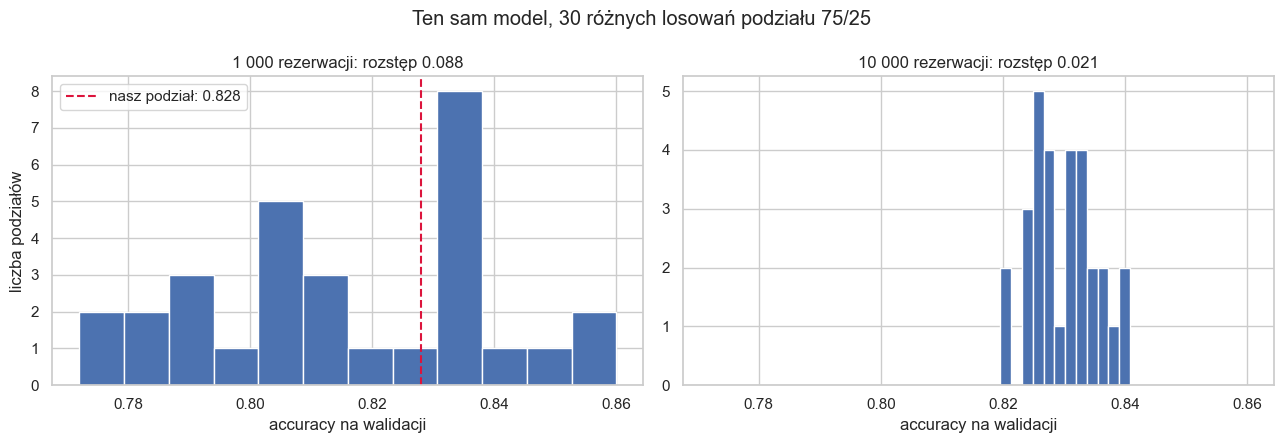

,min,max,rozstęp,odch. std
1 000 rezerwacji,0.772,0.860,0.088,0.024
10 000 rezerwacji,0.820,0.841,0.021,0.005


In [40]:
def rozrzut_podzialow(X, y, n_powtorzen=30):
    wyniki = []
    for rs in range(n_powtorzen):
        a, b, c, d = train_test_split(X, y, test_size=0.25, stratify=y, random_state=rs)
        wyniki.append(accuracy_score(d, zbuduj_model().fit(a, c).predict(b)))
    return np.array(wyniki)

rozrzut = {"1 000 rezerwacji": rozrzut_podzialow(X_1k, y_1k),
           "10 000 rezerwacji": rozrzut_podzialow(X, y)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for a, (nazwa, w) in zip(ax, rozrzut.items()):
    a.hist(w, bins=12, edgecolor="white")
    a.set_title(f"{nazwa}: rozstęp {w.max() - w.min():.3f}")
    a.set_xlabel("accuracy na walidacji")
ax[0].axvline(acc_bazowy, color="crimson", ls="--", label=f"nasz podział: {acc_bazowy:.3f}")
ax[0].legend(); ax[0].set_ylabel("liczba podziałów")
fig.suptitle("Ten sam model, 30 różnych losowań podziału 75/25")
plt.tight_layout(); plt.show()

pd.DataFrame({k: {"min": w.min(), "max": w.max(), "rozstęp": w.max() - w.min(), "odch. std": w.std()}
              for k, w in rozrzut.items()}).T.round(3)

**Odpowiedź:** na próbce 1 000 rezerwacji sam wybór podziału przesuwa accuracy nawet o **9 punktów procentowych** — bez zmiany czegokolwiek w modelu. Różnica po dodaniu miesiąca (−0,8 pp) jest ponad 10 razy mniejsza niż ten rozstęp. Na podstawie jednego podziału **nie da się** stwierdzić, że miesiąc coś zmienił (ani w górę, ani w dół).

Drugi wniosek z wykresu: **im mniej danych, tym bardziej pojedynczy podział kłamie.** Przy 10 000 rezerwacji rozrzut jest kilka razy mniejszy — ale nie zerowy, a różnice, które chcemy wykrywać przy ulepszaniu modelu, bywają równie małe. Jeśli Wasz zbiór ma kilkaset albo kilka tysięcy wierszy (a wiele popularnych zbiorów z Kaggle i UCI tyle ma), pojedynczy podział jest bardzo zawodny.

Potrzebujemy oceny, która **uśrednia szczęście w losowaniu** — to jest walidacja krzyżowa.

### 1.2 K-Fold: każdy wiersz raz jest w walidacji

```
dane:     [====|====|====|====|====]      dzielimy na K = 5 części (foldów)

runda 1:  [VAL ][ tr ][ tr ][ tr ][ tr ]   →  wynik_1
runda 2:  [ tr ][VAL ][ tr ][ tr ][ tr ]   →  wynik_2
runda 3:  [ tr ][ tr ][VAL ][ tr ][ tr ]   →  wynik_3
runda 4:  [ tr ][ tr ][ tr ][VAL ][ tr ]   →  wynik_4
runda 5:  [ tr ][ tr ][ tr ][ tr ][VAL ]   →  wynik_5

wynik CV = średnia ± odchylenie standardowe z 5 rund
```

* Każda obserwacja **dokładnie raz** trafia do walidacji, a model za każdym razem trenuje się na 80% danych.
* Dostajemy **5 wyników zamiast 1** → widzimy nie tylko średnią, ale i rozrzut.
* Ile foldów? Zwykle **5 lub 10**. Więcej foldów = więcej treningu na rundę i więcej obliczeń.
* Zbiór testowy nadal odkładamy na bok — CV zastępuje **walidację**, nie test.

**`KFold` vs `StratifiedKFold`:** w klasyfikacji chcemy, by **w każdym foldzie był ten sam odsetek klas**. Najlepiej widać to przy rzadkiej klasie — weźmy wersję hoteli, w której anulowań jest tylko **5%**:

In [41]:
# wersja "rzadka": wszystkie nieanulowane + tyle anulowanych, by stanowiły 5%
nie_anul = hotele[hotele["is_canceled"] == 0]
anul = hotele[hotele["is_canceled"] == 1].sample(int(len(nie_anul) * 0.05 / 0.95), random_state=RANDOM_STATE)
hotele_rzadkie = pd.concat([nie_anul, anul]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
X_r = hotele_rzadkie.drop(columns="is_canceled")
y_r = hotele_rzadkie["is_canceled"]
print(f"hotele_rzadkie: {len(hotele_rzadkie)} rezerwacji, anulowanych {y_r.mean():.1%} ({y_r.sum()} szt.)")

hotele_rzadkie: 6627 rezerwacji, anulowanych 5.0% (331 szt.)


In [42]:
from sklearn.model_selection import KFold, StratifiedKFold

for nazwa, podzial in [("KFold", KFold(n_splits=5, shuffle=True, random_state=0)),
                       ("StratifiedKFold", StratifiedKFold(n_splits=5, shuffle=True, random_state=0))]:
    liczby = [int(y_r.iloc[idx_val].sum()) for _, idx_val in podzial.split(X_r, y_r)]
    print(f"{nazwa:<16} anulowania w kolejnych foldach walidacyjnych: {liczby}")

KFold            anulowania w kolejnych foldach walidacyjnych: [65, 73, 57, 66, 70]
StratifiedKFold  anulowania w kolejnych foldach walidacyjnych: [66, 67, 66, 66, 66]


`KFold` losuje wiersze bez patrzenia na klasy, więc liczba przypadków pozytywnych w foldach „pływa”. `StratifiedKFold` pilnuje proporcji. Przy klasyfikacji **domyślnie** używamy wersji stratyfikowanej (i `shuffle=True` + `random_state`, żeby wynik był powtarzalny).

### 1.3 W kodzie: `cross_val_score` i `cross_validate`

In [43]:
from sklearn.model_selection import cross_val_score, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # JEDEN obiekt dla wszystkich klasyfikacji

wyniki = cross_val_score(zbuduj_model(), X_1k, y_1k, cv=cv, scoring="accuracy")
print("accuracy w foldach:", wyniki.round(4))
print(f"CV accuracy = {wyniki.mean():.4f} ± {wyniki.std():.4f}")

accuracy w foldach: [0.8   0.835 0.8   0.825 0.85 ]
CV accuracy = 0.8220 ± 0.0196


`cross_validate` robi to samo, ale potrafi więcej: **kilka metryk naraz**, czas treningu i — co ważne — **wynik na treningu** (`return_train_score=True`). Rozjazd train vs walidacja to nasz „termometr przeuczenia” z Zajęć 1.

In [44]:
res = cross_validate(zbuduj_model(), X_1k, y_1k, cv=cv,
                     scoring=["accuracy", "roc_auc"], return_train_score=True)
pd.DataFrame(res).drop(columns=["fit_time", "score_time"]).round(4)

,test_accuracy,train_accuracy,test_roc_auc,train_roc_auc
0,0.800,0.8512,0.8418,0.9359
1,0.835,0.8375,0.9102,0.9252
2,0.800,0.8500,0.8831,0.9289
3,0.825,0.8475,0.9233,0.9249
4,0.850,0.8375,0.9282,0.9224


In [45]:
print(f"accuracy train = {res['train_accuracy'].mean():.4f}   walidacja = {res['test_accuracy'].mean():.4f}")

accuracy train = 0.8448   walidacja = 0.8220


Train jest nieco wyżej niż walidacja (ok. 2 pp), a ta luka jest **porównywalna z rozrzutem między foldami** (odch. std ok. 2 pp) → nie widać wyraźnego przeuczenia modelu liniowego. Zwróćcie też uwagę, jak bardzo wyniki różnią się między foldami — to ten sam szum, co na histogramie.

❓ **Dlaczego do CV podajemy cały pipeline, a nie dane już przeskalowane i zakodowane?**

**Odpowiedź:** bo w każdej rundzie preprocessing musi uczyć się **tylko na foldach treningowych**. Gdybyśmy najpierw przeskalowali/zaimputowali cały zbiór, średnie i mediany „widziałyby” fold walidacyjny — to dokładnie ten sam data leakage, co skaler dopasowany na całych danych na Zajęciach 1. Pipeline w środku CV gwarantuje, że `fit` dzieje się osobno w każdej rundzie.

### 1.4 Porównanie modeli — uczciwie

Zasady:
1. Wynik podajemy jako **średnia ± odchylenie** z foldów.
2. Oba warianty oceniamy **na tych samych foldach** (ten sam obiekt `cv`).
3. Patrzymy na **różnice fold po foldzie**: czy wariant B wygrywa w każdej rundzie, czy raz tak, raz nie?

Wróćmy do pytania z początku — miesiąc przyjazdu:

In [46]:
def porownaj(model_a, model_b, X, y, cv, scoring="accuracy", nazwy=("A", "B")):
    a = cross_val_score(model_a, X, y, cv=cv, scoring=scoring)
    b = cross_val_score(model_b, X, y, cv=cv, scoring=scoring)
    tabela = pd.DataFrame({nazwy[0]: a, nazwy[1]: b, "różnica (B − A)": b - a},
                          index=[f"fold {i+1}" for i in range(len(a))])
    tabela.loc["średnia"] = tabela.mean()
    tabela.loc["odch. std"] = tabela.iloc[:-1].std(ddof=0)
    return tabela.round(4)

porownaj(zbuduj_model(), zbuduj_model(CECHY_KAT + ["arrival_date_month"]), X_1k, y_1k, cv,
         nazwy=("bazowy", "+ miesiąc"))

,bazowy,+ miesiąc,różnica (B − A)
fold 1,0.8000,0.8000,0.0000
fold 2,0.8350,0.8050,-0.0300
fold 3,0.8000,0.7950,-0.0050
fold 4,0.8250,0.8550,0.0300
fold 5,0.8500,0.8350,-0.0150
średnia,0.8220,0.8180,-0.0040
odch. std,0.0196,0.0232,0.0198


**Werdykt:** średnia różnica jest bliska zera, a w pojedynczych foldach różnice sięgają kilku punktów procentowych **w obie strony**. **Nie ma żadnych dowodów, że miesiąc przyjazdu pomaga** — „zmiana” z pojedynczego podziału mieści się w szumie. To nie to samo, co dowód, że miesiąc jest bezużyteczny: przy odchyleniu różnicy ok. 2 pp na 1 000 rezerwacjach efektu rzędu 0,5 pp po prostu **nie da się wykryć**.

❓ **Dlaczego oba modele muszą dostać ten sam obiekt `cv`?**

**Odpowiedź:** bo różne foldy to różne „poziomy trudności”. Fold 1 może być łatwiejszy od foldu 4 dla **każdego** modelu. Gdy oba warianty widzą te same foldy, ta trudność się znosi i porównujemy tylko modele. Przy innych foldach różnica wyników mieszałaby efekt modelu z efektem losowania.

### 1.5 Kiedy losowy podział kłamie

`KFold`/`StratifiedKFold` zakładają, że wiersze są **niezależne**. Dwa częste wyjątki:

| sytuacja | problem przy losowym podziale | narzędzie |
|---|---|---|
| ten sam klient / pacjent / sklep w wielu wierszach | model „rozpoznaje” klienta z treningu → zawyżony wynik | `GroupKFold` (cała grupa w jednym foldzie) |
| dane w czasie (sprzedaż, ceny) | model trenuje na przyszłości, ocenia na przeszłości | `TimeSeriesSplit` (walidacja zawsze później niż trening) |

Zasada: **walidacja ma udawać to, jak model będzie użyty**.

Sprawdźmy to na hotelach — tym razem na **pełnych 10 000 rezerwacji** z lat **2015–2017**. W praktyce hotel uczy model na przeszłości i używa go na **przyszłych** rezerwacjach. Porównamy dwie walidacje krzyżowe tego samego modelu:

* **`StratifiedKFold`** — foldy losowe, w walidacji są rezerwacje z całego okresu,
* **`TimeSeriesSplit`** — „walidacja krzyżowa w czasie”:

```
czas →      [ 1 ][ 2 ][ 3 ][ 4 ][ 5 ][ 6 ]

runda 1:    [ tr ][VAL]
runda 2:    [ tr ][ tr ][VAL]
runda 3:    [ tr ][ tr ][ tr ][VAL]
runda 4:    [ tr ][ tr ][ tr ][ tr ][VAL]
runda 5:    [ tr ][ tr ][ tr ][ tr ][ tr ][VAL]
```

* walidacja leży **zawsze później** niż trening — model nigdy nie zagląda w przyszłość,
* trening **rośnie** z rundy na rundę (jak w życiu: z czasem mamy więcej historii),
* dostajemy kilka wyników → średnia ± odchylenie, tak jak w zwykłym CV.

⚠️ `TimeSeriesSplit` nie zna dat — dzieli **po kolejności wierszy**. Dlatego dane trzeba najpierw **posortować po dacie**; na przemieszanych danych podział byłby znowu losowy.

In [47]:
from sklearn.model_selection import TimeSeriesSplit

# TimeSeriesSplit dzieli po KOLEJNOŚCI wierszy → najpierw sortujemy po dacie przyjazdu
data_przyjazdu = pd.to_datetime(
    X["arrival_date_year"].astype(str) + "-" + X["arrival_date_month"] + "-"
    + X["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
kolejnosc = data_przyjazdu.sort_values(kind="stable").index
X_czas, y_czas, daty = X.loc[kolejnosc], y.loc[kolejnosc], data_przyjazdu.loc[kolejnosc]

tss = TimeSeriesSplit(n_splits=5)

# co trafia do kolejnych rund?
pd.DataFrame([{"runda": nr,
               "trening (wierszy)": len(idx_tr),
               "walidacja (okres)": f"{daty.iloc[idx_val].min():%Y-%m} – {daty.iloc[idx_val].max():%Y-%m}",
               "anulowań w walidacji": round(y_czas.iloc[idx_val].mean(), 3)}
              for nr, (idx_tr, idx_val) in enumerate(tss.split(X_czas), start=1)]).set_index("runda")

,trening (wierszy),walidacja (okres),anulowań w walidacji
runda,,,
1,1670,2015-12 – 2016-05,0.328
2,3336,2016-05 – 2016-09,0.346
3,5002,2016-09 – 2017-01,0.373
4,6668,2017-01 – 2017-05,0.379
5,8334,2017-05 – 2017-08,0.415


Walidacja zawsze leży po treningu, a trening rośnie z rundy na rundę. Zwróćcie uwagę na ostatnią kolumnę: **odsetek anulowań rośnie w czasie** (z ok. 33% do ok. 42%) — warunki się zmieniają, a model musi sobie z tym poradzić. Teraz porównajmy oba sposoby walidacji:

In [48]:
wyniki_cv = {}
for nazwa, XX, yy, podzial in [("StratifiedKFold (losowo)", X, y, cv),
                               ("TimeSeriesSplit (w czasie)", X_czas, y_czas, tss)]:
    r = cross_validate(zbuduj_model(), XX, yy, cv=podzial, scoring=["accuracy", "roc_auc"])
    wyniki_cv[nazwa] = {"accuracy w foldach": r["test_accuracy"].round(3),
                        "accuracy": f'{r["test_accuracy"].mean():.3f} ± {r["test_accuracy"].std():.3f}',
                        "ROC-AUC": f'{r["test_roc_auc"].mean():.3f} ± {r["test_roc_auc"].std():.3f}'}
pd.DataFrame(wyniki_cv).T

,accuracy w foldach,accuracy,ROC-AUC
StratifiedKFold (losowo),"[0.844, 0.832, 0.83, 0.822, 0.829]",0.831 ± 0.007,0.910 ± 0.006
TimeSeriesSplit (w czasie),"[0.814, 0.789, 0.802, 0.814, 0.768]",0.797 ± 0.017,0.872 ± 0.029


Ten sam model, dwie walidacje krzyżowe — dwie różne odpowiedzi:

* **`TimeSeriesSplit` daje wyraźnie niższe wyniki** (accuracy ok. 0.80 vs 0.83, ROC-AUC ok. 0.87 vs 0.91). Accuracy w **każdej** rundzie czasowej jest niższa niż w najgorszym losowym foldzie — to nie jest szum.
* **Losowe CV jest zbyt optymistyczne:** model widzi w treningu rezerwacje z tych samych tygodni co walidacja, więc nie musi radzić sobie ze zmianą warunków (rosnący odsetek anulowań).
* **Rozrzut w `TimeSeriesSplit` jest większy** — rundy różnią się nie tylko danymi, ale też ilością historii (runda 1 uczy się na 1 670 rezerwacjach) i porą roku w walidacji.

To wynik z `TimeSeriesSplit` jest bliższą prawdy obietnicą dla revenue managera.

> **Dlaczego w dalszej części i tak używamy losowego CV?** Bo w sekcjach 2–4 **porównujemy metryki i modele między sobą** — do tego losowe CV wystarcza i jest prostsze. Gdybyśmy mieli obiecać revenue managerowi konkretny wynik na przyszłych rezerwacjach, podalibyśmy go z walidacji w czasie.

---
## 2. Metryki klasyfikacji

### 2.1 Macierz pomyłek

Od teraz wracamy do **pełnych 10 000 rezerwacji** — przy porównywaniu metryk stabilne liczby pomagają.

Do metryk potrzebujemy predykcji. Zamiast jednego podziału użyjemy `cross_val_predict` — każda obserwacja dostaje predykcję z modelu, który **jej nie widział** (out-of-fold).

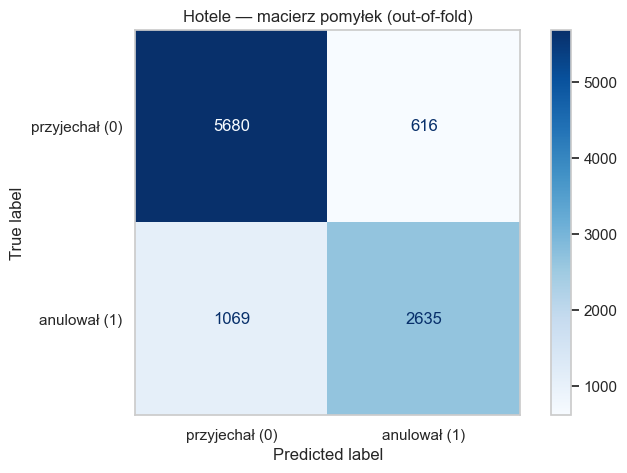

In [49]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

pred = cross_val_predict(zbuduj_model(), X, y, cv=cv)

ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["przyjechał (0)", "anulował (1)"],
                                        cmap="Blues", values_format="d")
plt.title("Hotele — macierz pomyłek (out-of-fold)"); plt.grid(False); plt.show()

| | przewidział **0** | przewidział **1** |
|---|---|---|
| **naprawdę 0** | TN — poprawnie „przyjedzie” | **FP** — fałszywy alarm (overbooking!) |
| **naprawdę 1** | **FN** — przegapiona anulacja (pusty pokój) | TP — trafiona anulacja |

To ta sama tabela, co w KPI biznesowym z Zajęć 1 — tam FP kosztował 150% wartości rezerwacji, a TP dawał 60%. **Każda metryka poniżej to inny sposób podsumowania tych czterech liczb.**

### 2.2 Precision, recall, F1

$$\text{precision} = \frac{TP}{TP + FP} \qquad\qquad \text{recall} = \frac{TP}{TP + FN} \qquad\qquad F_1 = 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

$$\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad\qquad \text{specificity} = \frac{TN}{TN + FP}$$

* **precision** — *gdy model mówi „anuluje”, jak często ma rację?*
* **recall** (czułość) — *jaki odsetek wszystkich anulacji model wyłapał?*
* **F1** — średnia harmoniczna obu; wysoka tylko wtedy, gdy **oba** są wysokie.

In [50]:
from sklearn.metrics import classification_report
print(classification_report(y, pred, target_names=["przyjechał (0)", "anulował (1)"], digits=3))

                precision    recall  f1-score   support

przyjechał (0)      0.842     0.902     0.871      6296
  anulował (1)      0.811     0.711     0.758      3704

      accuracy                          0.832     10000
     macro avg      0.826     0.807     0.814     10000
  weighted avg      0.830     0.832     0.829     10000



Którą metrykę stawiać na pierwszym miejscu, zależy od **kosztu błędu**:

| problem | groźniejszy błąd | patrzymy głównie na |
|---|---|---|
| overbooking (hotele, Zajęcia 1) | FP — gość przyjeżdża, a pokoju nie ma | **precision** |
| wykrywanie choroby, fraudu | FN — przegapiony przypadek | **recall** |
| oba błędy podobnie kosztowne | — | **F1** |

### 2.3 Paradoks accuracy

Przejdźmy na `hotele_rzadkie` (5% anulowań). Porównajmy „model”, który **zawsze** mówi „nie anuluje”, z regresją logistyczną:

In [51]:
from sklearn.dummy import DummyClassifier

METRYKI = ["accuracy", "precision", "recall", "f1"]

def tabela_metryk(modele, X, y, cv, scoring):
    wiersze = {}
    for nazwa, m in modele.items():
        r = cross_validate(m, X, y, cv=cv, scoring=scoring)
        wiersze[nazwa] = {k: r[f"test_{k}"].mean() for k in scoring}
    return pd.DataFrame(wiersze).T.round(3)

tabela_metryk({"Dummy (zawsze 0)": DummyClassifier(strategy="most_frequent"),
               "regresja logistyczna": zbuduj_model()},
              X_r, y_r, cv, METRYKI)

,accuracy,precision,recall,f1
Dummy (zawsze 0),0.950,0.000,0.000,0.00
regresja logistyczna,0.967,0.921,0.366,0.52


Model, który **nic nie robi**, ma 95% accuracy — bo 95% rezerwacji i tak nie jest anulowanych. Recall = 0: nie wyłapał ani jednej anulacji. Accuracy przy niezbalansowanych klasach jest **bezużyteczne jako główna metryka**. Precision, recall i F1 od razu demaskują Dummy: same zera.

Zwróćcie uwagę na regresję logistyczną: precision wysoka, ale recall niski — przy progu 0.5 model działa bardzo ostrożnie. Do tego wrócimy przy kalibracji.

### 2.4 Metryki rankingowe: ROC-AUC vs PR-AUC

Precision, recall i F1 zależą od **progu** (domyślnie 0.5). Metryki rankingowe oceniają same prawdopodobieństwa: *czy przypadki pozytywne dostają wyższe p niż negatywne?* — niezależnie od progu.

* **ROC-AUC** — pole pod krzywą TPR (recall) vs FPR. 0.5 = losowo, 1.0 = idealnie.
* **PR-AUC** — pole pod krzywą precision vs recall. Poziom losowy = odsetek klasy pozytywnej

Dla każdego progu $t$ liczymy:

$$\text{TPR}(t) = \frac{TP(t)}{TP(t) + FN(t)} \;(= \text{recall}) \qquad\qquad \text{FPR}(t) = \frac{FP(t)}{FP(t) + TN(t)}$$

Krzywa ROC to punkty $\big(\text{FPR}(t),\, \text{TPR}(t)\big)$ dla wszystkich progów.

**PR-AUC** w sklearn to **average precision** — precision ważona przyrostami recall po kolejnych progach:

$$\text{AP} = \sum_{k} \big(R_k - R_{k-1}\big)\cdot P_k$$

gdzie $k$ numeruje kolejne progi od najwyższego do najniższego, $P_k$ i $R_k$ to precision i recall przy $k$-tym progu, a $R_0 = 0$.

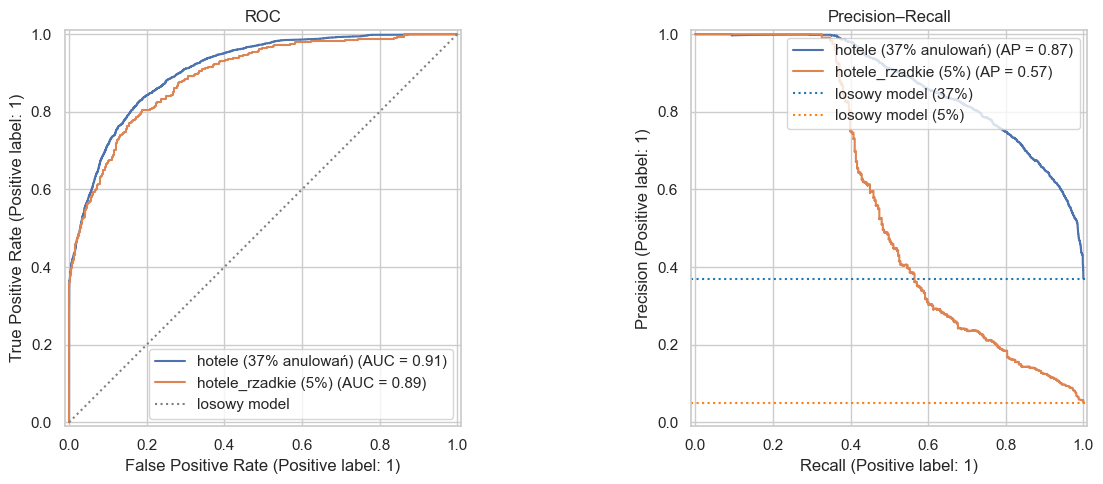

In [52]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

p_pelne = cross_val_predict(zbuduj_model(), X, y, cv=cv, method="predict_proba")[:, 1]
p_rzadkie = cross_val_predict(zbuduj_model(), X_r, y_r, cv=cv, method="predict_proba")[:, 1]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for yy, pp, etykieta in [(y, p_pelne, "hotele (37% anulowań)"), (y_r, p_rzadkie, "hotele_rzadkie (5%)")]:
    RocCurveDisplay.from_predictions(yy, pp, ax=ax[0], name=etykieta)
    PrecisionRecallDisplay.from_predictions(yy, pp, ax=ax[1], name=etykieta)
ax[0].plot([0, 1], [0, 1], ls=":", color="gray", label="losowy model")
ax[1].axhline(y.mean(), ls=":", color="tab:blue", label=f"losowy model (37%)")
ax[1].axhline(y_r.mean(), ls=":", color="tab:orange", label=f"losowy model (5%)")
ax[0].set_title("ROC"); ax[1].set_title("Precision–Recall")
ax[0].legend(loc="lower right"); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

In [53]:
from sklearn.metrics import roc_auc_score, average_precision_score
pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y, p_pelne), roc_auc_score(y_r, p_rzadkie)],
    "PR-AUC": [average_precision_score(y, p_pelne), average_precision_score(y_r, p_rzadkie)],
    "PR-AUC losowego modelu": [y.mean(), y_r.mean()],
}, index=["hotele (37%)", "hotele_rzadkie (5%)"]).round(3)

,ROC-AUC,PR-AUC,PR-AUC losowego modelu
hotele (37%),0.909,0.872,0.37
hotele_rzadkie (5%),0.893,0.566,0.05


**ROC-AUC prawie się nie zmienia** (ok. 0.9 w obu wersjach), choć zadanie na rzadkich danych jest dużo trudniejsze. **PR-AUC spada wyraźnie** — bo precision bezpośrednio odczuwa, że przy rzadkiej klasie każdy fałszywy alarm „rozmywa” garstkę trafień.

Reguła praktyczna: **przy rzadkiej klasie pozytywnej główną metryką rankingową jest PR-AUC**, a jej wynik porównujemy z odsetkiem klasy pozytywnej

### 2.5 Metryki probabilistyczne: log-loss i Brier

Czasem liczy się nie ranking, a **sama wartość prawdopodobieństwa** (np. bank wylicza oczekiwaną stratę = p × kwota). Wtedy:

$$\text{Brier} = \frac{1}{n}\sum_{i=1}^{n} \big(\hat p_i - y_i\big)^2 \qquad\qquad \text{log-loss} = -\frac{1}{n}\sum_{i=1}^{n} \Big[\, y_i \log \hat p_i + (1 - y_i)\log\big(1 - \hat p_i\big) \Big]$$

* **Brier** — błąd średniokwadratowy prawdopodobieństwa. 0 = ideał.
* **log-loss** — ta sama funkcja straty, którą minimalizuje regresja logistyczna; bardzo mocno karze **pewne siebie pomyłki**:

Obie: **im mniej, tym lepiej**. Punkt odniesienia: Dummy, który zawsze zwraca odsetek klasy pozytywnej.

In [54]:
from sklearn.metrics import brier_score_loss, log_loss

p_dummy = np.full(len(y_r), y_r.mean())
pd.DataFrame({
    "Brier": [brier_score_loss(y_r, p_dummy), brier_score_loss(y_r, p_rzadkie)],
    "log-loss": [log_loss(y_r, p_dummy), log_loss(y_r, p_rzadkie)],
}, index=["Dummy (zawsze 5%)", "regresja logistyczna"]).round(4)

,Brier,log-loss
Dummy (zawsze 5%),0.0475,0.1984
regresja logistyczna,0.0295,0.1190


### 2.6 Jak wybrać metrykę — i podać ją do CV

1. **Zdecyduj biznesowo**, który błąd jest groźniejszy i czy liczy się decyzja (próg), ranking czy samo prawdopodobieństwo.
2. Wybierz **jedną metrykę główną** (nią porównujesz warianty) i 1–2 pomocnicze.
3. Podaj je do `cross_validate`:

| sytuacja | metryka główna | `scoring=` |
|---|---|---|
| klasy zbalansowane, oba błędy podobne | accuracy / F1 | `"accuracy"`, `"f1"` |
| rzadka klasa, liczy się ranking | PR-AUC | `"average_precision"` |
| liczy się wartość p (ryzyko, wycena) | Brier / log-loss | `"neg_brier_score"`, `"neg_log_loss"` |

> sklearn zawsze **maksymalizuje** `scoring`, dlatego metryki-błędy mają prefiks `neg_` (wartości ujemne: bliżej zera = lepiej).

❓ **Model A ma PR-AUC = 0.30, model B = 0.25. Dane mają 2% klasy pozytywnej. Czy oba modele są słabe?**

**Odpowiedź:** nie. Losowy model miałby PR-AUC ≈ 0.02, więc oba są ok. 12–15× lepsze od losowego. PR-AUC zawsze czytamy względem odsetka klasy pozytywnej, a nie względem 0.5 czy 1.0. Żeby stwierdzić, czy A jest lepszy od B, i tak potrzebujemy wyniku z CV ze średnią i odchyleniem.

---
## 3. Metryki regresji

Wracamy do California Housing i dwóch modeli z demo Zajęć 1: zwykłej regresji liniowej i „GAM” (splajny + Ridge). Tym razem **przez CV i z większą liczbą metryk**.

In [55]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor

kalifornia["BedrmsShare"] = kalifornia["AveBedrms"] / kalifornia["AveRooms"]   # cecha z Zajęć 1
Xk = kalifornia.drop(columns="MedHouseVal")
yk = kalifornia["MedHouseVal"]

cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # regresja: zwykły KFold

METRYKI_REG = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error",
               "MedAE": "neg_median_absolute_error", "MAPE": "neg_mean_absolute_percentage_error",
               "R²": "r2"}

modele_reg = {
    "Dummy (średnia)": DummyRegressor(strategy="mean"),
    "regresja liniowa": make_pipeline(StandardScaler(), LinearRegression()),
    "GAM: splajny + Ridge": make_pipeline(StandardScaler(), SplineTransformer(n_knots=8, degree=3), Ridge(alpha=1.0)),
}

wiersze = {}
for nazwa, m in modele_reg.items():
    r = cross_validate(m, Xk, yk, cv=cv_reg, scoring=METRYKI_REG)
    wiersze[nazwa] = {k: r[f"test_{k}"].mean() for k in METRYKI_REG}
tab_reg = pd.DataFrame(wiersze).T
tab_reg[["MAE", "RMSE", "MedAE", "MAPE"]] *= -1          # z "neg_" z powrotem na dodatnie błędy
tab_reg.round(3)

,MAE,RMSE,MedAE,MAPE,R²
Dummy (średnia),0.912,1.154,0.763,0.621,-0.001
regresja liniowa,0.525,0.722,0.405,0.314,0.609
GAM: splajny + Ridge,0.480,0.666,0.361,0.279,0.667


Co mówi każda kolumna:

| metryka | pełna nazwa | wzór | pytanie, na które odpowiada |
|---|---|---|---|
| **MAE** | Mean Absolute Error — średni błąd bezwzględny | $\frac{1}{n}\sum_i \lvert y_i - \hat y_i \rvert$ | o ile przeciętnie się mylimy? |
| **RMSE** | Root Mean Squared Error — pierwiastek z błędu średniokwadratowego | $\sqrt{\frac{1}{n}\sum_i (y_i - \hat y_i)^2}$ | j.w., ale duże pomyłki ważą więcej |
| **MedAE** | Median Absolute Error — mediana błędu bezwzględnego | $\operatorname{mediana}\,\lvert y_i - \hat y_i \rvert$ | o ile mylimy się w **typowym** przypadku? |
| **MAPE** | Mean Absolute Percentage Error — średni bezwzględny błąd procentowy | $\frac{1}{n}\sum_i \frac{\lvert y_i - \hat y_i \rvert}{\lvert y_i \rvert}$ | o ile **procent** się mylimy? |
| **R²** | coefficient of determination — współczynnik determinacji | $1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$ | jaką część zmienności targetu wyjaśnia model? |

Uwaga: RMSE ≥ MAE **zawsze**, z samej definicji — więc sam fakt, że RMSE jest większe, nic nie mówi. Patrzymy na **stosunek**: gdyby błędy miały rozkład normalny, RMSE/MAE ≈ 1.25; tu GAM ma ok. 0.666 / 0.480 ≈ 1.39, a MedAE jest wyraźnie niższe od MAE. Błędy mają więc nieco cięższy ogon: typowa dzielnica jest przewidywana nieźle, a część dużych pomyłek (m.in. drogie dzielnice z obciętym targetem) podbija średnie metryki.

### 3.1 Pułapki MAPE i R²

**MAPE** dzieli błąd przez prawdziwą wartość — więc **eksploduje, gdy y jest bliskie zera**:

In [56]:
from sklearn.metrics import mean_absolute_percentage_error, mean_absolute_error

y_prawda = np.array([100.0, 100.0, 0.5])     # np. sprzedaż w trzech sklepach
y_pred   = np.array([ 90.0, 110.0, 1.5])     # każda pomyłka: 10, 10 i 1 sztuka
print(f"MAE  = {mean_absolute_error(y_prawda, y_pred):.2f} sztuki")
print("błędy procentowe:", (np.abs(y_prawda - y_pred) / y_prawda).round(2), "<- pomyłka o 1 sztukę przy y = 0.5 to 200%")
print(f"MAPE = {mean_absolute_percentage_error(y_prawda, y_pred):.0%}   <- jeden mały sklep zdominował całą metrykę")

MAE  = 7.00 sztuki
błędy procentowe: [0.1 0.1 2. ] <- pomyłka o 1 sztukę przy y = 0.5 to 200%
MAPE = 73%   <- jeden mały sklep zdominował całą metrykę


Dodatkowo MAPE jest **asymetryczne**: przewidywanie za nisko może dać co najwyżej 100% błędu, za wysoko — dowolnie dużo. Model optymalizowany pod MAPE ma więc skłonność do **zaniżania**.

**R²** zależy od zmienności targetu w danym zbiorze — R² = 0.6 na jednym zbiorze i 0.6 na innym to **nie** ta sama jakość. Porównujemy R² tylko na tych samych danych.

### 3.2 Adjusted R² — kara za cechy bez wartości

Zwykłe R² **na treningu nigdy nie maleje**, gdy dokładamy cechy — nawet czysty szum. Statystyka ma na to poprawkę:

$$R^2_{adj} = 1 - (1 - R^2)\cdot\frac{n - 1}{n - p - 1}$$

gdzie $n$ = liczba obserwacji, $p$ = liczba cech. Każda dodatkowa cecha musi poprawić R² na tyle, by „opłacić” utratę jednego stopnia swobody. W scikit-learn nie ma gotowej funkcji — liczymy ją sami.

Eksperyment: mała próbka (150 dzielnic), 4 sensowne cechy, a potem dokładamy kolejne kolumny **czystego szumu**:

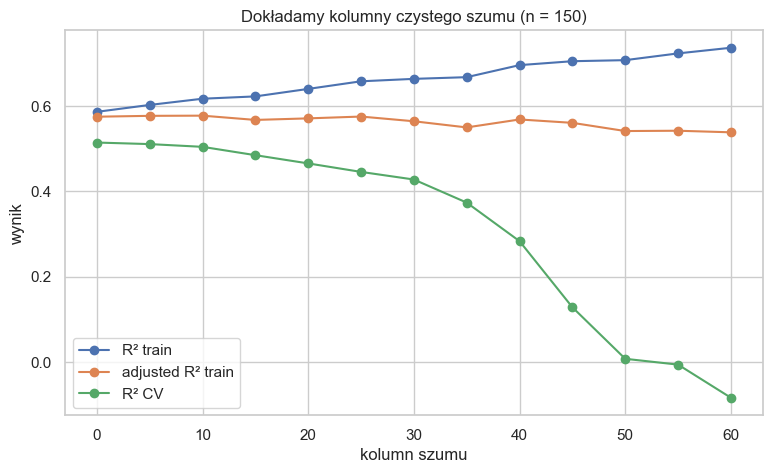

,kolumn szumu,R² train,adjusted R² train,R² CV
0,0,0.586,0.575,0.514
3,15,0.623,0.567,0.485
6,30,0.664,0.564,0.428
9,45,0.705,0.561,0.128
12,60,0.737,0.538,-0.084


In [57]:
from sklearn.metrics import r2_score

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

proba = kalifornia.sample(150, random_state=RANDOM_STATE)
X_baza = proba[["MedInc", "HouseAge", "Latitude", "Longitude"]]
y_baza = proba["MedHouseVal"]
szum = pd.DataFrame(np.random.default_rng(0).normal(size=(len(proba), 60)),
                    index=proba.index, columns=[f"szum_{j}" for j in range(60)])

wyniki_szum = []
for k in range(0, 61, 5):
    Xs = pd.concat([X_baza, szum.iloc[:, :k]], axis=1)
    n, p = Xs.shape
    r2_tr = r2_score(y_baza, LinearRegression().fit(Xs, y_baza).predict(Xs))
    r2_cv = cross_val_score(LinearRegression(), Xs, y_baza, cv=cv_reg, scoring="r2").mean()
    wyniki_szum.append({"kolumn szumu": k, "R² train": r2_tr,
                        "adjusted R² train": adjusted_r2(r2_tr, n, p), "R² CV": r2_cv})
wyniki_szum = pd.DataFrame(wyniki_szum)

ax = wyniki_szum.plot(x="kolumn szumu", marker="o", figsize=(9, 5))
ax.set_ylabel("wynik"); ax.set_title("Dokładamy kolumny czystego szumu (n = 150)")
plt.show()
wyniki_szum.round(3).iloc[::3]

Trzy linie, trzy zachowania:

* **R² train rośnie** z każdą kolumną szumu — model „dopasowuje się” do przypadkowych liczb. Gdybyśmy wybierali model po R² na treningu, wybralibyśmy ten z największą liczbą śmieci.
* **Adjusted R²** nie daje się nabrać — stoi w miejscu, a przy dużej liczbie cech spada.
* **R² z CV** spada najmocniej — bo pokazuje, co się dzieje **na nowych danych**: szum aktywnie szkodzi.

Adjusted R² to narzędzie, gdy oceniamy model **na tych samych danych, na których go uczyliśmy** (typowe w statystyce). W ML mamy walidację/CV, które z natury karzą za bezużyteczne cechy — dlatego na co dzień patrzymy na R² z CV. Adjusted R² warto znać: pojawia się w raportach, w `statsmodels` i na rozmowach rekrutacyjnych.

### 3.3 Target po logarytmie: `TransformedTargetRegressor`

Na Zajęciach 1: gdy trenujemy na `log1p(y)`, metryki trzeba liczyć **po odwróceniu** `expm1` — inaczej błąd jest „w logarytmach”. `TransformedTargetRegressor` robi to automatycznie i trzyma oba kroki w jednym obiekcie, więc działa w CV jak każdy model:

In [58]:
from sklearn.compose import TransformedTargetRegressor

gam = make_pipeline(StandardScaler(), SplineTransformer(n_knots=8, degree=3), Ridge(alpha=1.0))
gam_log = TransformedTargetRegressor(regressor=gam, func=np.log1p, inverse_func=np.expm1)

wiersze = {}
for nazwa, m in {"GAM, target oryginalny": gam, "GAM, target log1p": gam_log}.items():
    r = cross_validate(m, Xk, yk, cv=cv_reg, scoring=METRYKI_REG)
    wiersze[nazwa] = {k: r[f"test_{k}"].mean() for k in METRYKI_REG}
tab_log = pd.DataFrame(wiersze).T
tab_log[["MAE", "RMSE", "MedAE", "MAPE"]] *= -1
tab_log.round(3)

,MAE,RMSE,MedAE,MAPE,R²
"GAM, target oryginalny",0.480,0.666,0.361,0.279,0.667
"GAM, target log1p",0.457,0.660,0.317,0.247,0.673


Oba wiersze są w **tych samych jednostkach** (setki tys. USD), więc można je uczciwie porównać. Logarytm zmienia to, **na które błędy model zwraca uwagę**: uczy się błędów względnych, a nie bezwzględnych. Tutaj poprawił wszystkie metryki, ale najmocniej MAPE i MedAE

---
## 4. Kalibracja prawdopodobieństwa

### 4.1 Motywacja

Na Zajęciach 1 wyliczyliśmy, że w hotelu opłaca się odsprzedać pokój, gdy **p(anulowanie) > 0.71**. To wyliczenie zakłada, że `predict_proba = 0.8` znaczy naprawdę „80% takich rezerwacji zostanie anulowanych”. **Czy to prawda?**

Model jest **dobrze skalibrowany**, jeśli wśród przypadków, którym dał p ≈ 0.3, faktycznie ~30% jest pozytywnych.

### 4.2 Diagnoza: krzywa kalibracji

Grupujemy predykcje w przedziały (np. 10 przedziałów po równo obserwacji) i dla każdego porównujemy **średnie przewidywane p** z **faktycznym odsetkiem pozytywnych**. Ideał = przekątna.

Porównamy na `hotele_rzadkie` dwa modele:
* zwykłą regresję logistyczną,
* regresję logistyczną z `class_weight="balanced"` — popularny „trik” na rzadką klasę: błędy na klasie pozytywnej ważą tyle razy więcej, ile razy jest rzadsza.

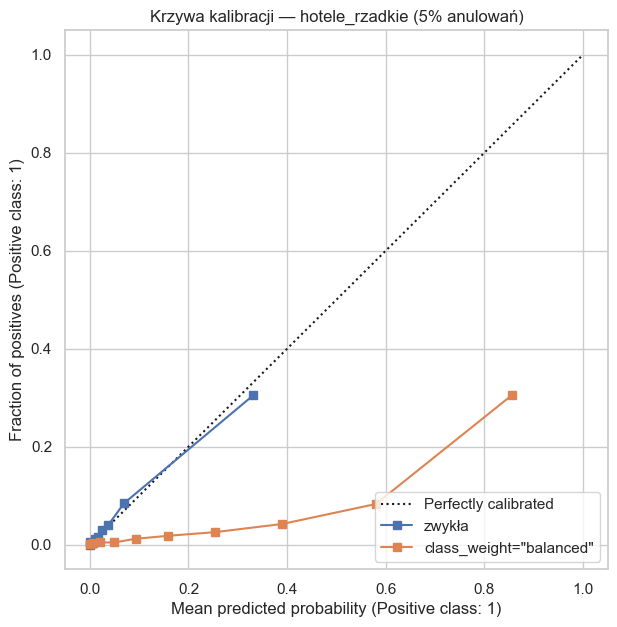

faktyczny odsetek anulowań:           0.050
średnie p — zwykła:                    0.050
średnie p — class_weight="balanced":   0.241


In [59]:
from sklearn.calibration import CalibrationDisplay

p_zwykla = p_rzadkie                                            # już policzone w sekcji 2
p_balanced = cross_val_predict(zbuduj_model(class_weight="balanced"), X_r, y_r, cv=cv,
                               method="predict_proba")[:, 1]

fig, ax = plt.subplots(figsize=(7, 7))
CalibrationDisplay.from_predictions(y_r, p_zwykla, n_bins=10, strategy="quantile", ax=ax, name="zwykła")
CalibrationDisplay.from_predictions(y_r, p_balanced, n_bins=10, strategy="quantile", ax=ax, name='class_weight="balanced"')
ax.set_title("Krzywa kalibracji — hotele_rzadkie (5% anulowań)")
plt.show()

print(f"faktyczny odsetek anulowań:           {y_r.mean():.3f}")
print(f"średnie p — zwykła:                    {p_zwykla.mean():.3f}")
print(f'średnie p — class_weight="balanced":   {p_balanced.mean():.3f}')

* **Zwykła regresja logistyczna** leży blisko przekątnej — średnio przewiduje dokładnie tyle anulowań, ile jest naprawdę. To nie przypadek: log-loss, który minimalizuje, „nagradza” prawdziwe prawdopodobieństwa. Dlatego zwykła regresja logistyczna to dobry punkt odniesienia dla kalibracji.
* **`class_weight="balanced"`** leży daleko pod przekątną: przewiduje średnio kilka razy więcej anulowań, niż ich jest. Udaje, że klasy są pół na pół — i tak też przewiduje.

In [60]:
modele_kal = {"zwykła": zbuduj_model(), 'class_weight="balanced"': zbuduj_model(class_weight="balanced")}
tabela_metryk(modele_kal, X_r, y_r, cv, ["recall", "precision", "roc_auc", "average_precision", "neg_brier_score"])

,recall,precision,roc_auc,average_precision,neg_brier_score
zwykła,0.366,0.921,0.893,0.567,-0.030
"class_weight=""balanced""",0.755,0.202,0.888,0.557,-0.112


`balanced` ma dużo wyższy **recall przy progu 0.5** (bo wszystkie p są zawyżone, więcej przypadków przekracza 0.5) i prawie ten sam ranking (ROC-AUC, PR-AUC). Ale jego **Brier jest kilka razy gorszy** — prawdopodobieństwa nie nadają się do liczenia pieniędzy. Gdybyśmy na nim liczyli KPI z progiem 0.71, decyzje byłyby błędne.

### 4.3 Naprawa: `CalibratedClassifierCV`

`CalibratedClassifierCV` uczy model, a potem — na danych, których model nie widział (wewnętrzne CV) — uczy **funkcję poprawiającą** jego prawdopodobieństwa:

* `method="sigmoid"` — dopasowuje krzywą w kształcie S; mało parametrów, bezpieczna przy małych danych.
* `method="isotonic"` — dowolna funkcja rosnąca; elastyczna, ale potrzebuje więcej danych i może się przeuczyć.

Obie są **niemalejące** → nie zmieniają kolejności obserwacji → ROC-AUC zostaje (prawie) taki sam.

In [61]:
from sklearn.calibration import CalibratedClassifierCV

modele_kal["balanced + sigmoid"] = CalibratedClassifierCV(zbuduj_model(class_weight="balanced"), method="sigmoid", cv=5)
modele_kal["balanced + isotonic"] = CalibratedClassifierCV(zbuduj_model(class_weight="balanced"), method="isotonic", cv=5)

tabela_metryk(modele_kal, X_r, y_r, cv, ["roc_auc", "average_precision", "neg_brier_score", "neg_log_loss", "recall"])

,roc_auc,average_precision,neg_brier_score,neg_log_loss,recall
zwykła,0.893,0.567,-0.030,-0.119,0.366
"class_weight=""balanced""",0.888,0.557,-0.112,-0.347,0.755
balanced + sigmoid,0.891,0.560,-0.030,-0.122,0.342
balanced + isotonic,0.892,0.558,-0.030,-0.133,0.354


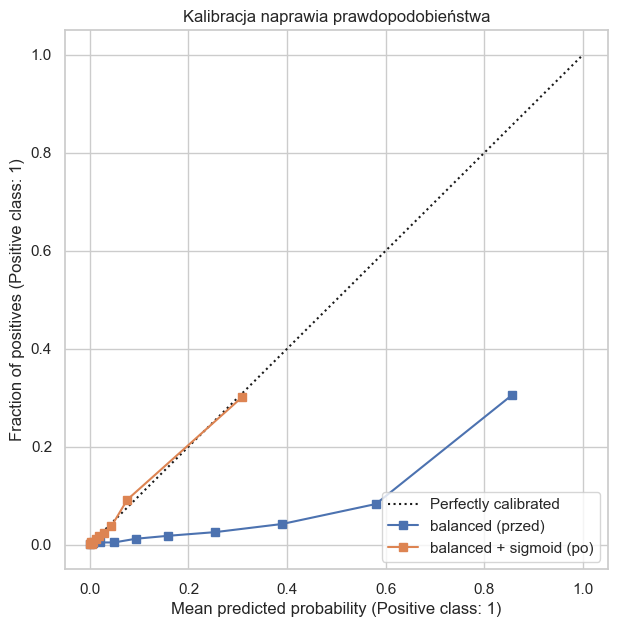

In [62]:
p_sigmoid = cross_val_predict(modele_kal["balanced + sigmoid"], X_r, y_r, cv=cv, method="predict_proba")[:, 1]

fig, ax = plt.subplots(figsize=(7, 7))
CalibrationDisplay.from_predictions(y_r, p_balanced, n_bins=10, strategy="quantile", ax=ax, name='balanced (przed)')
CalibrationDisplay.from_predictions(y_r, p_sigmoid, n_bins=10, strategy="quantile", ax=ax, name="balanced + sigmoid (po)")
ax.set_title("Kalibracja naprawia prawdopodobieństwa"); plt.show()

Co się zmieniło po kalibracji:

* **Brier i log-loss** wracają do poziomu zwykłej regresji logistycznej — prawdopodobieństwa znów są wiarygodne.
* **ROC-AUC i PR-AUC prawie bez zmian** — kalibracja to funkcja rosnąca, więc **nie zmienia kolejności** przypadków. Ranking zostaje, poprawiają się tylko wartości.
* **Recall przy progu 0.5 spada** z powrotem — bo p nie są już sztucznie zawyżone. To nie wada: próg to osobna, **biznesowa** decyzja (Zajęcia 1). Najpierw wiarygodne p, potem próg dobrany do kosztów.

---
## 5. Podsumowanie

**Trzy zasady rzetelnej oceny:**
1. **Jedna liczba bez odchylenia nic nie znaczy.** Oceniamy przez CV, porównujemy na tych samych foldach, patrzymy na różnice fold po foldzie. Im mniej danych, tym większy szum — a walidacja ma udawać to, jak model będzie użyty (np. podział czasowy).
2. **Metrykę wybiera problem, nie wygoda.** Accuracy przy rzadkiej klasie kłamie; PR-AUC czytamy względem odsetka klasy pozytywnej; w regresji MAE/RMSE/MedAE odpowiadają na różne pytania.
3. **Jeśli decyzja zależy od wartości p — sprawdź kalibrację.** Krzywa kalibracji + Brier; naprawa przez `CalibratedClassifierCV`.

**Ściąga:**

| potrzeba | narzędzie |
|---|---|
| ocena przez CV | `StratifiedKFold` / `KFold` + `cross_validate(..., scoring=[...], return_train_score=True)` |
| dane w czasie / grupy | `TimeSeriesSplit`, `GroupKFold` |
| predykcje „spoza próby” do wykresów | `cross_val_predict(..., method="predict_proba")` |
| klasyfikacja | `classification_report`, `average_precision`, `roc_auc`, `neg_brier_score` |
| regresja | `neg_mean_absolute_error`, `neg_root_mean_squared_error`, `neg_median_absolute_error`, `r2` (+ adjusted R² ręcznie) |
| target po logarytmie | `TransformedTargetRegressor` |
| kalibracja | `CalibrationDisplay`, `CalibratedClassifierCV` |

**Co dalej (część 2):** każde porównanie wariantów przygotowania danych — imputacja, outliery, kodowanie, selekcja cech — będziemy już robić **przez CV**, tak jak tutaj.

---
## Dodatek: Klasyfikacja wieloklasowa (dla chętnych)

> Ta część korzysta z obiektów z sekcji 0–2 (`zbuduj_model`, `cv`, `tabela_metryk`, `hotele`), więc najpierw uruchom notebook od początku.

Do tej pory klasy były dwie. Co, jeśli jest ich **K > 2**? Przykład na znanych danych: przewidujemy **segment rynku** rezerwacji (`market_segment`) — 7 klas o bardzo nierównej liczności.

Z cech usuwamy:
* `market_segment` — to teraz target,
* `distribution_channel` — kanał sprzedaży jest niemal kopią segmentu (zadanie stałoby się trywialne),
* `is_canceled` — w chwili przyjęcia rezerwacji jeszcze go nie znamy.

Model się nie zmienia: `LogisticRegression` sama obsługuje wiele klas — zamiast sigmoidy używa **softmax**, który zwraca K prawdopodobieństw sumujących się do 1.

In [63]:
y_seg = hotele["market_segment"]
X_seg = hotele.drop(columns=["market_segment", "distribution_channel", "is_canceled"])
cechy_kat_seg = [c for c in CECHY_KAT if c not in ("market_segment", "distribution_channel")]
model_seg = zbuduj_model(cechy_kat=cechy_kat_seg)

y_seg.value_counts().to_frame("liczba rezerwacji").assign(udział=lambda d: (d["liczba rezerwacji"] / len(y_seg)).round(3))

,liczba rezerwacji,udział
market_segment,,
Online TA,4728,0.473
Offline TA/TO,2059,0.206
Groups,1613,0.161
Direct,1055,0.106
Corporate,462,0.046
Complementary,63,0.006
Aviation,20,0.002


### B.1 Macierz pomyłek K × K

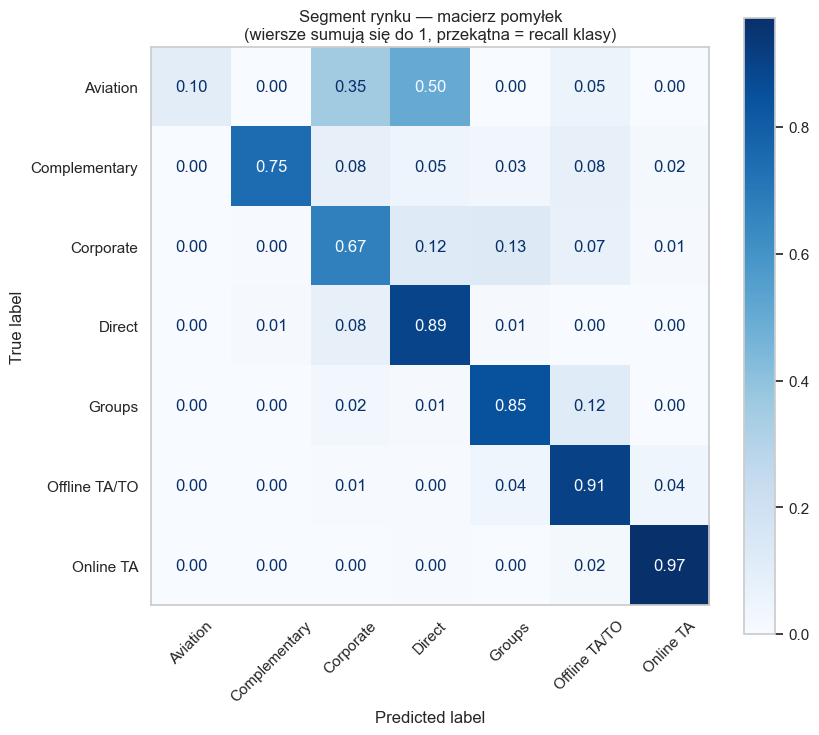

In [64]:
pred_seg = cross_val_predict(model_seg, X_seg, y_seg, cv=cv)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_seg, pred_seg, normalize="true", values_format=".2f",
                                        cmap="Blues", ax=ax, xticks_rotation=45)
ax.set_title("Segment rynku — macierz pomyłek\n(wiersze sumują się do 1, przekątna = recall klasy)")
ax.grid(False); plt.show()

Każdy **wiersz** to prawdziwa klasa i sumuje się do 1, więc **przekątna to recall każdej klasy**. Poza przekątną widać, *z czym* model myli: np. `Aviation` (rezerwacje dla linii lotniczych) model myli głównie z `Direct` i `Corporate` — co ma sens: to też rezerwacje robione bez biura podróży.

### B.2 Metryki per klasa i trzy sposoby uśredniania

In [65]:
print(classification_report(y_seg, pred_seg, digits=3, zero_division=0))

               precision    recall  f1-score   support

     Aviation      0.333     0.100     0.154        20
Complementary      0.723     0.746     0.734        63
    Corporate      0.675     0.671     0.673       462
       Direct      0.896     0.895     0.896      1055
       Groups      0.890     0.847     0.868      1613
Offline TA/TO      0.847     0.906     0.876      2059
    Online TA      0.981     0.971     0.976      4728

     accuracy                          0.913     10000
    macro avg      0.764     0.734     0.740     10000
 weighted avg      0.913     0.913     0.912     10000



Jak złożyć metryki z K klas w jedną liczbę — trzy sposoby uśredniania:

| uśrednianie | każda klasa waży | kiedy używać |
|---|---|---|
| **macro** | tyle samo | wszystkie klasy są tak samo ważne — także rzadkie |
| **weighted** | proporcjonalnie do liczności | liczy się jakość „na przeciętną obserwację” |

In [66]:
tabela_metryk({"Dummy (zawsze Online TA)": DummyClassifier(strategy="most_frequent"),
               "regresja logistyczna": model_seg},
              X_seg, y_seg, cv, ["accuracy", "f1_macro", "f1_weighted"])

,accuracy,f1_macro,f1_weighted
Dummy (zawsze Online TA),0.473,0.092,0.304
regresja logistyczna,0.913,0.738,0.912


### B.3 Metryki rankingowe i probabilistyczne dla K klas

**ROC-AUC** dla K klas liczymy na dwa sposoby:
  * **one-vs-rest (OvR)**, `"roc_auc_ovr"` — K binarnych AUC „klasa k vs **wszystkie pozostałe**”, potem średnia. Odpowiada na pytanie: *czy model potrafi wyłowić każdą klasę z tłumu?*
  * **one-vs-one (OvO)**, `"roc_auc_ovo"` — osobne AUC dla **każdej pary** klas, liczone tylko na obserwacjach z tych dwóch klas (przy 7 klasach: 21 par), potem średnia. Odpowiada na pytanie: *czy model odróżnia od siebie każdą parę klas — także te trudne?*

  OvR bywa zawyżone: w „rest” dominują duże, łatwe do odróżnienia klasy, które rozwadniają trudne pomyłki. OvO daje każdej parze tę samą wagę, więc jest surowsze i nie zależy od liczności klas.

In [67]:
tabela_metryk({"Dummy (proporcje klas)": DummyClassifier(strategy="prior"),
               "regresja logistyczna": model_seg},
              X_seg, y_seg, cv, ["roc_auc_ovr", "roc_auc_ovo", "neg_log_loss"])

,roc_auc_ovr,roc_auc_ovo,neg_log_loss
Dummy (proporcje klas),0.50,0.500,-1.398
regresja logistyczna,0.99,0.975,-0.236
